# FFNN classification — will this conjunction end up high risk?

**FYS-STK3155, Project 3.** Data: the ESA Collision Avoidance Challenge
conjunction data messages (CDMs).

## The question

Each *event* is a predicted close approach between an operational satellite and
another object. Over the days before the Time of Closest Approach (TCA) a
sequence of CDMs is issued, each with a refined collision risk
$r = \log_{10} P_c$. An operator must decide **two days before TCA** whether the
event deserves attention, because a collision-avoidance manoeuvre takes time to
plan and costs fuel.

We therefore predict, using only CDMs with `time_to_tca >= 2`:

$$ y = \mathbb{1}\left[\,r_{\text{final}} \ge -6\,\right], \qquad\text{i.e. } P_c \ge 10^{-6}. $$

## What makes this hard

## Data representation

All three models in this project (RNN, FFNN, XGBoost) share one pipeline in
`read_data.build_shared_datasets`: a single stratified event-level split, a
log10 transform of the heavy-tailed covariance columns, median imputation,
standardisation and a PCA on the ~96 orbital-geometry/covariance columns —
every step fitted on training events only. `time_to_tca`, the three
risk-derived columns and the two categoricals bypass the PCA, because PCA
keeps high-*variance* directions, not high-*predictive* ones, and `risk` is
the strongest predictor there is. The RNN consumes the resulting CDM-level
sequences; this notebook and XGBoost consume their **per-event aggregate**:
mean, standard deviation, first and last value of every sequence column, plus
the number of CDMs.

Only **66 of 8 293** eligible events are positive (0.80 %). After a 70/15/15
event-level split that leaves roughly 46 / 10 / 10 positives. Ten positives
cannot support a stable comparison of nine activation/initialisation
combinations, so **every model-selection number in this notebook is a 5-fold
stratified cross-validation mean ± standard deviation** computed on the
development set (train + validation, 56 positives), and the test split is not
touched until the very last section.

A false negative — a missed high-risk conjunction — is far more costly than a
false positive, which merely costs an analyst's time. The primary selection
metric is therefore $F_2$, which weights recall four times as heavily as
precision, and the training loss is class-weighted binary cross-entropy.

## Notebook outline

| § | Experiment |
|---|---|
| 1 | Setup, data loading, event-level split |
| 2 | Exploratory data analysis |
| 3 | Activation function × weight initialisation (3×3) |
| 4 | Loss function: weighted BCE vs. differentiable soft-$F_2$ |
| 5 | Network architecture |
| 6 | Learning rate × weight decay (`GridSearchCV`) |
| 7 | Decision threshold selection |
| 8 | Ablation: is the current risk estimate doing all the work? |
| 9 | Learning curves of the selected model |
| 10 | Final held-out test evaluation |
| 11 | Benchmark against classical baselines |

## 1. Setup

In [1]:
from __future__ import annotations

import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch

# `read_data`, `ffnn_core` and `plot_style` live next to this notebook.
sys.path.insert(0, str(Path.cwd()))

import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    fbeta_score,
    make_scorer,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict

import ffnn_core as fc
import plot_style as ps
import read_data as rd

warnings.filterwarnings("ignore", category=UserWarning)
ps.apply_style()

### Experiment configuration

Everything that the experiments hold fixed lives here, so that a comparison
never differs in more than the one thing it is supposed to compare.

In [2]:
SEED = 3155

# --- data representation ---------------------------------------------------
VARIANCE_THRESHOLD = 0.95      # share of variance the PCA keeps (~49 of 96 columns)
INCLUDE_CURRENT_RISK = True    # see §8 for the ablation
VAL_SIZE, TEST_SIZE = 0.15, 0.15

# --- fixed training settings shared by every comparison --------------------
BASE_HIDDEN = (100, 100)
BASE_ACTIVATION = "relu"
BASE_INIT = "he"
BASE_LR = 1e-3
BASE_WEIGHT_DECAY = 0.0
BATCH_SIZE = 64
MAX_EPOCHS = 150
PATIENCE = 20                  # early stopping on validation PR-AUC
GRAD_CLIP = 5.0

#: Filled in by §4 once the loss function is chosen; every later `base_clf()`
#: call picks it up, so the architecture / hyperparameter / final-model
#: sections all train with the selected loss.
LOSS_OVERRIDES: dict = {}

# --- cross-validation ------------------------------------------------------
CV_FOLDS = 5
N_JOBS = 7                     # parallel folds; each worker is single-threaded

RESULTS_DIR = Path("..") / "results" / "classification"
(RESULTS_DIR / "figures").mkdir(parents=True, exist_ok=True)
(RESULTS_DIR / "tables").mkdir(parents=True, exist_ok=True)

# One torch thread per process: the models are tiny, so parallelism pays off
# across CV folds rather than inside a single matrix multiply.
torch.set_num_threads(1)

fc.set_seed(SEED)
DEVICE = fc.get_device()
print(f"PyTorch {torch.__version__} | device: {DEVICE}")
print(f"Results -> {RESULTS_DIR.resolve()}")

PyTorch 2.15.0+cpu | device: cpu
Results -> /home/kevintannum/UiO/FYS-STK3155--Project3--UiO/results/classification


### Loading the shared datasets

`build_shared_datasets` enforces the order that keeps the evaluation honest:

1. split **events** (stratified on the binary target),
2. fit the log-transform / imputer / scaler / PCA / one-hot encoder on the
   **training events' CDMs only**,
3. transform every split, then aggregate each event to one row.

Because each event is collapsed to exactly one row before anything is
fitted, two CDMs from the same event cannot end up in different splits; the
function asserts that the event ids are unique and the check is repeated
here.

In [3]:
from sklearn.preprocessing import StandardScaler

t0 = time.perf_counter()
shared = rd.build_shared_datasets(
    variance_threshold=VARIANCE_THRESHOLD, include_current_risk=INCLUDE_CURRENT_RISK,
    val_size=VAL_SIZE, test_size=TEST_SIZE, seed=SEED,
)
print(f"built in {time.perf_counter() - t0:.0f} s")

agg, meta = shared["aggregate"], shared["event_meta"]
y_train, y_val, y_test = (shared["y_class"][k] for k in ("train", "val", "test"))
y_all = np.concatenate([y_train, y_val, y_test])

# The aggregates are built from standardised columns but are not themselves
# standardised (a std is >= 0, a mean of a one-hot is in [0, 1]), so a scaler
# is fitted on the training rows and applied to the other two splits.
scaler = StandardScaler().fit(agg["train"])
X_train = scaler.transform(agg["train"]).astype(np.float32)
X_val = scaler.transform(agg["val"]).astype(np.float32)
X_test = scaler.transform(agg["test"]).astype(np.float32)
feature_names = list(agg["train"].columns)

# The *development* set = train + validation. All model selection happens here,
# through 5-fold stratified CV; the test set stays frozen until §10.
X_dev = np.vstack([X_train, X_val])
y_dev = np.concatenate([y_train, y_val])

N_FEATURES = X_dev.shape[1]
print(f"PCA: {shared['n_components']} components for {VARIANCE_THRESHOLD:.0%} of the variance; "
      f"{len(shared['sequence_columns'])} sequence columns -> {N_FEATURES} aggregate features")
split_summary = pd.DataFrame(
    [
        {"split": name, "events": len(yy), "positives": int(yy.sum()),
         "positive rate": yy.mean()}
        for name, yy in [("train", y_train), ("validation", y_val),
                         ("test", y_test), ("dev = train+val", y_dev)]
    ]
)
print(split_summary.to_string(index=False))
ps.save_table(split_summary, "split_summary", RESULTS_DIR)

ids = shared["event_ids"]
assert not (set(ids["train"]) & set(ids["val"]))
assert not (set(ids["train"]) & set(ids["test"]))
assert not (set(ids["val"]) & set(ids["test"]))
print("\nevent-level split verified: no event id appears in two splits")

shared datasets: 8293 events | PCA keeps 48 of 96 columns for 95% variance | log10 on 15 columns | 76 sequence columns


built in 22 s
PCA: 48 components for 95% of the variance; 76 sequence columns -> 233 aggregate features
          split  events  positives  positive rate
          train    5805         46       0.007924
     validation    1244         10       0.008039
           test    1244         10       0.008039
dev = train+val    7049         56       0.007944
  saved ../results/classification/tables/split_summary.csv

event-level split verified: no event id appears in two splits


### Class weighting and the cross-validation scheme

`pos_weight = n_neg / n_pos` is recomputed **inside each fold** from that
fold's training rows only (`pos_weight="auto"` in `TorchFFNNClassifier`), so
the weighting never sees the held-out fold.

In [4]:
CV = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)

#: Multi-metric scoring. `f2` is the selection metric; the rest are reported.
#: `f2`, `recall` and `precision` go through `predict()` and therefore use the
#: estimator's `threshold` (0.5 by default) — the threshold itself is tuned
#: separately in §7. `pr_auc` and `roc_auc` are threshold-free.
SCORING = {
    "f2": make_scorer(fbeta_score, beta=2, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "precision": make_scorer(precision_score, zero_division=0),
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
}

print(f"dev pos_weight = {(len(y_dev) - y_dev.sum()) / y_dev.sum():.1f}")
print(f"{CV_FOLDS}-fold stratified CV -> ~{int(y_dev.sum()) // CV_FOLDS} positives per held-out fold")


def base_clf(**overrides) -> fc.TorchFFNNClassifier:
    """The shared FFNN configuration; experiments override one thing at a time."""
    params = dict(
        hidden_dims=BASE_HIDDEN,
        activation=BASE_ACTIVATION,
        initialization=BASE_INIT,
        loss_name="bce",
        pos_weight="auto",
        lr=BASE_LR,
        weight_decay=BASE_WEIGHT_DECAY,
        batch_size=BATCH_SIZE,
        max_epochs=MAX_EPOCHS,
        patience=PATIENCE,
        grad_clip=GRAD_CLIP,
        seed=SEED,
        device=DEVICE,
    )
    params.update(LOSS_OVERRIDES)
    params.update(overrides)
    return fc.TorchFFNNClassifier(**params)


def run_grid(estimator, param_grid, X, y, refit="f2", cv=None) -> pd.DataFrame:
    """Run `GridSearchCV` and return a tidy mean ± std table.

    `GridSearchCV` handles the stratified folds, the parallelism and the score
    bookkeeping; the fitting inside each fold is still the PyTorch loop in
    `ffnn_core.train_model`.
    """
    gs = GridSearchCV(
        estimator, param_grid, scoring=SCORING, refit=refit,
        cv=cv or CV, n_jobs=N_JOBS, return_train_score=False,
    )
    t = time.perf_counter()
    gs.fit(X, y)
    elapsed = time.perf_counter() - t

    res = pd.DataFrame(gs.cv_results_)
    keep = [c for c in res.columns if c.startswith("param_")]
    keep += [f"mean_test_{m}" for m in SCORING] + [f"std_test_{m}" for m in SCORING]
    keep += ["mean_fit_time", "std_fit_time"]
    out = res[keep].copy()
    out.columns = [c.replace("mean_test_", "").replace("std_test_", "std_")
                   .replace("param_", "") for c in out.columns]
    print(f"  {len(res)} configs x {CV_FOLDS} folds in {elapsed:.0f} s "
          f"(best {refit} = {gs.best_score_:.3f})")
    return out.sort_values(refit, ascending=False).reset_index(drop=True), gs


def cv_ensemble(estimator, X, y, cv=None):
    """Fit one model per CV fold; return out-of-fold probabilities and the models.

    The out-of-fold probabilities are what the decision threshold is tuned on
    (§7). Averaging the *same* fold models at test time keeps the probability
    scale the threshold was chosen on. A single model refitted on all of the
    development data stops at a different epoch and lands on a different
    probability scale, which §10 demonstrates.
    """
    from joblib import Parallel, delayed
    from sklearn.base import clone

    cv = cv or CV
    folds = list(cv.split(X, y))

    def _fit(tr, va):
        t = time.perf_counter()
        m = clone(estimator).fit(X[tr], y[tr])
        return m, va, m.predict_proba(X[va])[:, 1], time.perf_counter() - t

    fitted = Parallel(n_jobs=min(N_JOBS, len(folds)))(delayed(_fit)(tr, va) for tr, va in folds)
    oof = np.zeros(len(y))
    models, fit_time = [], 0.0
    for m, va, p, t in fitted:
        oof[va] = p
        models.append(m)
        fit_time += t
    return oof, models, fit_time


def ensemble_proba(models, X):
    """Mean positive-class probability over a list of fitted fold models."""
    return np.mean([m.predict_proba(X)[:, 1] for m in models], axis=0)


def best_f2_threshold(y, proba):
    """Max-F2 threshold over the quantiles of `proba`; returns (threshold, f2)."""
    cand = np.unique(np.quantile(proba, np.linspace(0, 1, 401)))
    scores = np.array([fbeta_score(y, (proba >= t).astype(int), beta=2, zero_division=0)
                       for t in cand])
    k = int(np.argmax(scores))
    return float(cand[k]), float(scores[k])

dev pos_weight = 124.9
5-fold stratified CV -> ~11 positives per held-out fold


## 2. Exploratory data analysis

Three things worth knowing before any model is fitted: how rare the positive
class is, how much history each event carries, and whether the classes are
separable at all in the raw feature space.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


  saved ../results/classification/figures/01_data_overview.png


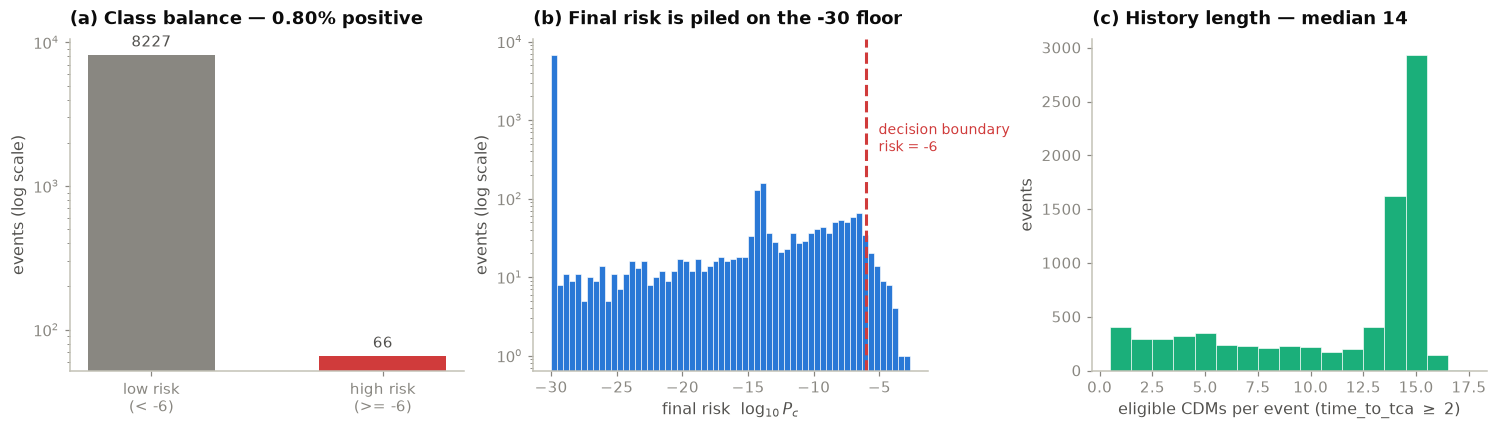

fraction of events whose final risk sits exactly on the -30 floor: 82.5%


In [5]:
meta_all = pd.concat([meta["train"], meta["val"], meta["test"]], ignore_index=True)
meta_dev = pd.concat([meta["train"], meta["val"]], ignore_index=True)

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))

# (a) class balance — a single hue, because the x-axis already names the classes
ax = axes[0]
counts = [int((y_all == 0).sum()), int((y_all == 1).sum())]
bars = ax.bar(["low risk\n(< -6)", "high risk\n(>= -6)"], counts,
              color=[ps.INK_MUTED, ps.STATUS["critical"]], width=0.55)
ax.bar_label(bars, fmt="%d", fontsize=9.5, color=ps.INK_SECONDARY, padding=3)
ax.set_yscale("log")
ax.set_ylabel("events (log scale)")
ax.set_title(f"(a) Class balance — {y_all.mean():.2%} positive")
ps.grid_y_only(ax)

# (b) final risk of every event, with the decision boundary marked
ax = axes[1]
y_cont = meta_all["final_risk"].values
ax.hist(y_cont, bins=60, color=ps.SERIES[0], edgecolor="white", linewidth=0.4)
ax.axvline(rd.HIGH_RISK_THRESHOLD, color=ps.STATUS["critical"], linewidth=2, linestyle="--")
ax.annotate("decision boundary\nrisk = -6", xy=(rd.HIGH_RISK_THRESHOLD, 0.7),
            xycoords=("data", "axes fraction"), xytext=(8, 0), textcoords="offset points",
            fontsize=9, color=ps.STATUS["critical"], va="center")
ax.set_yscale("log")
ax.set_xlabel(r"final risk  $\log_{10} P_c$")
ax.set_ylabel("events (log scale)")
ax.set_title("(b) Final risk is piled on the -30 floor")
ps.grid_y_only(ax)

# (c) how many CDMs an event contributes before the cutoff
ax = axes[2]
n_cdms = meta_all["n_cdms"].values
ax.hist(n_cdms, bins=np.arange(0.5, n_cdms.max() + 1.5), color=ps.SERIES[2],
        edgecolor="white", linewidth=0.4)
ax.set_xlabel("eligible CDMs per event (time_to_tca $\\geq$ 2)")
ax.set_ylabel("events")
ax.set_title(f"(c) History length — median {int(np.median(n_cdms))}")
ps.grid_y_only(ax)

ps.save_fig(fig, "01_data_overview", RESULTS_DIR)
plt.show()

print(f"fraction of events whose final risk sits exactly on the -30 floor: "
      f"{np.mean(y_cont <= -29.999):.1%}")

Two observations that shape everything below.

* **(b)** The risk scale is censored: 82 % of events end at exactly $-30$, the
  reporting floor. The classification target is therefore a thin tail of a
  heavily censored distribution — and the regression notebook has to confront
  the same floor directly.
* **(c)** Most events carry 10–17 CDMs before the cutoff; the aggregate
  features summarise that whole history (mean / std / first / last), so the
  model sees both the latest state and how it got there.

  saved ../results/classification/figures/02_feature_space.png


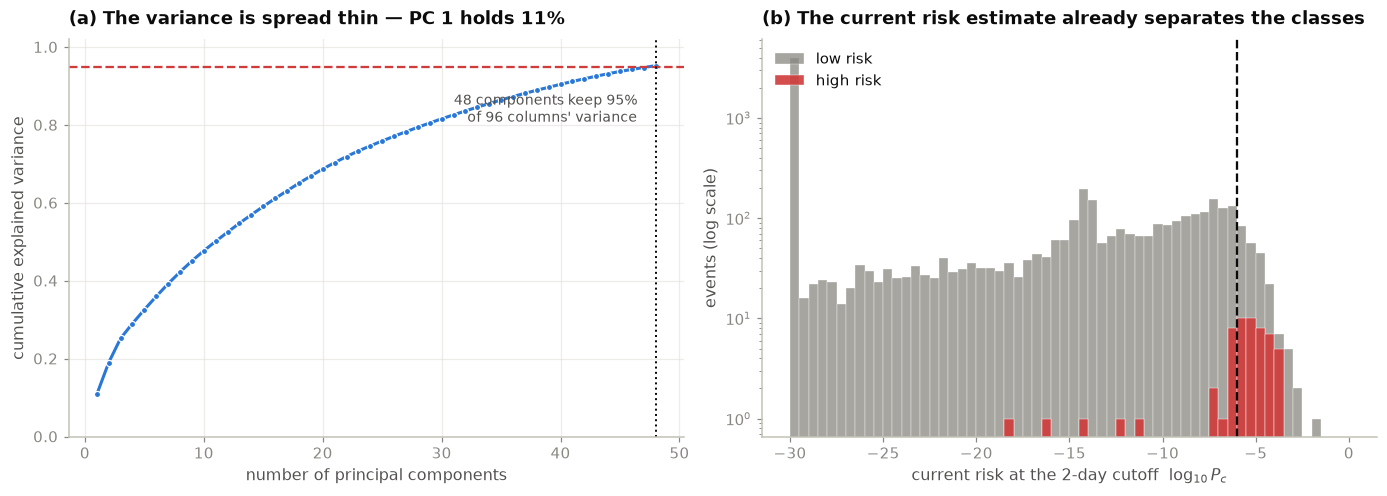

In [6]:
# How much does the PCA actually compress? And how informative is the one
# feature that bypasses it?
cum_var = np.cumsum(shared["explained_variance_ratio"])
n_pca_in = len(shared["pca_columns"])

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))

ax = axes[0]
ax.plot(np.arange(1, len(cum_var) + 1), cum_var, color=ps.SERIES[0], marker="o",
        markersize=4, markeredgecolor="white", markeredgewidth=0.8)
ax.axhline(VARIANCE_THRESHOLD, color=ps.STATUS["critical"], linestyle="--", linewidth=1.5)
ax.axvline(shared["n_components"], color=ps.INK, linestyle=":", linewidth=1.3)
ax.annotate(f"{shared['n_components']} components keep {VARIANCE_THRESHOLD:.0%}\nof {n_pca_in} columns' variance",
            xy=(shared["n_components"], VARIANCE_THRESHOLD), xytext=(-12, -36),
            textcoords="offset points", ha="right", fontsize=9, color=ps.INK_SECONDARY)
ax.set_xlabel("number of principal components")
ax.set_ylabel("cumulative explained variance")
ax.set_ylim(0, 1.02)
ax.set_title(f"(a) The variance is spread thin — PC 1 holds {cum_var[0]:.0%}")
ax.grid(True, alpha=0.6)

# The single most informative raw feature, by construction of the problem.
ax = axes[1]
risk_dev = meta_dev["last_risk"].values
bins = np.linspace(-30, 0, 61)
ax.hist(risk_dev[y_dev == 0], bins=bins, color=ps.INK_MUTED, alpha=0.75,
        label="low risk", edgecolor="white", linewidth=0.3)
ax.hist(risk_dev[y_dev == 1], bins=bins, color=ps.STATUS["critical"], alpha=0.9,
        label="high risk", edgecolor="white", linewidth=0.3)
ax.axvline(rd.HIGH_RISK_THRESHOLD, color=ps.INK, linewidth=1.5, linestyle="--")
ax.set_yscale("log")
ax.set_xlabel(r"current risk at the 2-day cutoff  $\log_{10} P_c$")
ax.set_ylabel("events (log scale)")
ax.set_title("(b) The current risk estimate already separates the classes")
ax.legend(loc="upper left")
ps.grid_y_only(ax)

ps.save_fig(fig, "02_feature_space", RESULTS_DIR)
plt.show()

Panel (a) is why the PCA keeps about half of the geometry columns rather
than a handful: no small set of directions dominates. Panel (b) is the reason
`risk` bypasses the PCA and the reason §8 runs an ablation: the value already
present in the last pre-cutoff CDM is *not* leakage — an operator can read it
two days before TCA — but it is so informative that it is worth asking how
much of the model's performance it alone accounts for.

## 3. Activation function × weight initialisation

A fixed `[100, 100]` network, the same learning rate, batch size, class
weighting and early-stopping rule throughout; only the hidden-layer activation
and the initialiser change. All 9 combinations are evaluated by 5-fold
stratified CV on the development set.

The initialisers all draw $W_{ij}\sim\mathcal{N}(0,\sigma^2)$ and differ only in
$\sigma^2$: LeCun $1/n_\text{in}$, Xavier $2/(n_\text{in}+n_\text{out})$, He
$2/n_\text{in}$ (slope-corrected for Leaky ReLU). Biases start at zero and the
output layer always uses Xavier, so the grid varies the hidden layers only.

In [7]:
ACTIVATIONS = ["sigmoid", "relu", "leaky_relu"]
INITS = ["lecun", "xavier", "he"]

act_init_results, _ = run_grid(
    base_clf(),
    {"activation": ACTIVATIONS, "initialization": INITS},
    X_dev, y_dev,
)
act_init_results = act_init_results.rename(
    columns={"activation": "activation", "initialization": "initialization"}
)
ps.save_table(act_init_results, "03_activation_initialization", RESULTS_DIR)
print(act_init_results[["activation", "initialization", "f2", "std_f2",
                        "pr_auc", "recall", "precision", "mean_fit_time"]].to_string(index=False))

  9 configs x 5 folds in 78 s (best f2 = 0.226)
  saved ../results/classification/tables/03_activation_initialization.csv
activation initialization       f2   std_f2   pr_auc   recall  precision  mean_fit_time
   sigmoid          lecun 0.225717 0.051228 0.116328 0.486364   0.106565       9.999972
leaky_relu             he 0.160242 0.087810 0.084433 0.269697   0.102736       6.364329
   sigmoid         xavier 0.152659 0.104752 0.101086 0.284848   0.074412      11.652144
leaky_relu          lecun 0.151282 0.097986 0.082390 0.212121   0.091191      10.175325
leaky_relu         xavier 0.147057 0.132654 0.093327 0.212121   0.083654       8.438944
   sigmoid             he 0.145720 0.125430 0.108885 0.321212   0.062937      19.109639
      relu         xavier 0.120114 0.088873 0.089453 0.162121   0.111912       7.362992
      relu          lecun 0.116791 0.090551 0.088653 0.175758   0.072277       9.463495
      relu             he 0.077842 0.067553 0.062323 0.106061   0.063775       7.90592

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


  saved ../results/classification/figures/03_activation_initialization.png


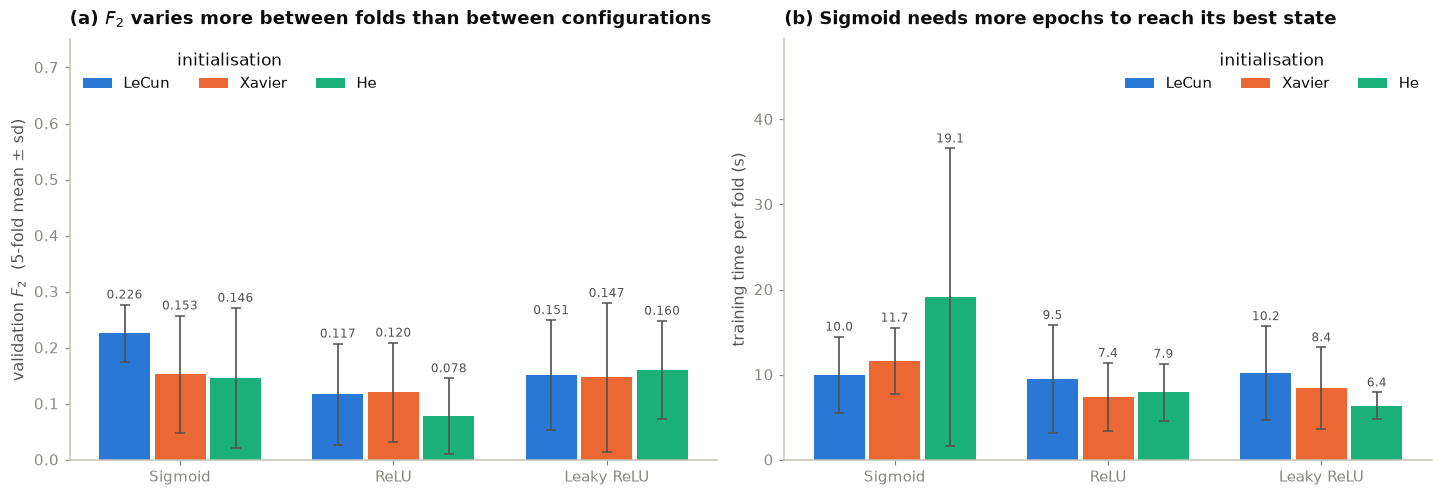

selected: activation = sigmoid, initialization = lecun (F2 = 0.226 +/- 0.051)


In [8]:
ACT_LABELS = {"sigmoid": "Sigmoid", "relu": "ReLU", "leaky_relu": "Leaky ReLU"}
INIT_LABELS = {"lecun": "LeCun", "xavier": "Xavier", "he": "He"}


def grouped_bars(ax, df, value, err=None, *, group="activation", series="initialization",
                 groups=None, series_order=None, fmt="{:.3f}"):
    """Grouped bar chart: one bar group per `group`, one colour per `series`."""
    groups = groups or ACTIVATIONS
    series_order = series_order or INITS
    x = np.arange(len(groups))
    width = 0.26
    for k, s in enumerate(series_order):
        vals, errs = [], []
        for g in groups:
            row = df[(df[group] == g) & (df[series] == s)]
            vals.append(float(row[value].iloc[0]) if len(row) else np.nan)
            errs.append(float(row[err].iloc[0]) if (err and len(row)) else 0.0)
        offset = (k - (len(series_order) - 1) / 2) * width
        bars = ax.bar(x + offset, vals, width * 0.92, label=INIT_LABELS.get(s, s),
                      color=ps.SERIES[k],
                      yerr=errs if err else None, capsize=3,
                      error_kw=dict(ecolor=ps.INK_SECONDARY, lw=1.1))
        # Direct labels: the secondary encoding that keeps the comparison
        # readable without relying on hue alone.
        ax.bar_label(bars, fmt=fmt.format, fontsize=8, color=ps.INK_SECONDARY, padding=2)
    ax.set_xticks(x, [ACT_LABELS.get(g, g) for g in groups])
    ps.grid_y_only(ax)


fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

ax = axes[0]
grouped_bars(ax, act_init_results, "f2", "std_f2")
ax.set_ylabel(r"validation $F_2$  (5-fold mean $\pm$ sd)")
ax.set_title(r"(a) $F_2$ varies more between folds than between configurations")
ax.legend(title="initialisation", ncols=3, loc="upper left")
ax.set_ylim(0, max(0.75, act_init_results["f2"].max() * 1.55))

ax = axes[1]
grouped_bars(ax, act_init_results, "mean_fit_time", "std_fit_time", fmt="{:.1f}")
ax.set_ylabel("training time per fold (s)")
ax.set_title("(b) Sigmoid needs more epochs to reach its best state")
ax.set_ylim(0, (act_init_results["mean_fit_time"] + act_init_results["std_fit_time"]).max() * 1.35)
ax.legend(title="initialisation", ncols=3, loc="upper right")

ps.save_fig(fig, "03_activation_initialization", RESULTS_DIR)
plt.show()

best_act_init = act_init_results.iloc[0]
BEST_ACTIVATION = best_act_init["activation"]
BEST_INIT = best_act_init["initialization"]
print(f"selected: activation = {BEST_ACTIVATION}, initialization = {BEST_INIT} "
      f"(F2 = {best_act_init['f2']:.3f} +/- {best_act_init['std_f2']:.3f})")

The standard deviations across folds are of the same size as the differences
between configurations. With roughly 11 positives in each held-out fold a
single event moving across the threshold changes $F_2$ by several points, so
the ranking should be read as "nothing here is clearly better than anything
else" rather than as a winner. We carry the top configuration forward because
a choice has to be made, not because it is significantly better.

## 4. Loss function: adding explicit false-negative pressure

Weighted BCE penalises a missed positive $w = n_\text{neg}/n_\text{pos}
\approx 125$ times more than a false alarm, which is the textbook
cost-sensitive recipe (Elkan 2001). It is a *proper scoring rule*, so the
probabilities it produces are calibrated, and for calibrated probabilities the
$F_\beta$-optimal classifier is simply a threshold (Lipton, Elkan &
Naryanaswamy 2014) — which is what §7 does.

The ESA challenge, however, scores on $F_2$ directly, so it is worth asking
whether putting $F_2$ *into the training objective* helps. Three candidates:

**BCE + soft-$F_2$ penalty** — the same construction as the L1/L2 experiment
in the regression study, a penalty term added to the base loss:

$$\mathcal{L} = \text{BCE}_w + \lambda\,\big(1 - F_2^{\text{soft}}\big),\qquad
F_2^{\text{soft}} = \frac{5\,\mathrm{TP}}{5\,\mathrm{TP} + 4\,\mathrm{FN} + \mathrm{FP}},$$

with expected counts $\mathrm{TP}=\sum p_i y_i$, $\mathrm{FP}=\sum p_i(1-y_i)$,
$\mathrm{FN}=\sum(1-p_i)y_i$. $F_2^{\text{soft}}$ is the Tversky index of
Salehi et al. (2017) with weights 0.8 on FN and 0.2 on FP, and the additive
"BCE + Tversky" form is the standard combination in segmentation (Taghanaki
et al. 2019). $\lambda = 0$ recovers weighted BCE exactly.

**Focal loss** (Lin et al. 2017):
$\mathcal{L} = -\alpha_t (1-p_t)^{\gamma}\log p_t$ with $\alpha_t = w$ for
positives. The $(1-p_t)^\gamma$ factor silences the thousands of easy
negatives so the few hard positives dominate the gradient; $\gamma = 0$
recovers weighted BCE.

**MSE / soft-$F_2$** — the ratio form of the ESA score, kept for reference.

One practical point: $F_2^{\text{soft}}$ is *non-decomposable* — a property of
the whole batch, not a sum over samples. With 0.8 % positives, a batch of 64
contains a positive only ~40 % of the time, and on the other steps the term
contributes nothing. The $F_2$-based losses are therefore trained with a batch
of 512 (≈ 4 positives per batch on average), and weighted BCE is run at both
batch sizes so that the effect of the batch is separated from the effect of
the loss.

In [9]:
F2_BATCH_SIZE = 512
F2_LAMBDAS = [0.0, 0.1, 0.3, 1.0, 3.0, 10.0]
FOCAL_GAMMA = 2.0

LOSS_CONFIGS = [("Weighted BCE, batch 64", dict(loss_name="bce", batch_size=BATCH_SIZE))]
for lam in F2_LAMBDAS:
    label = "Weighted BCE, batch 512" if lam == 0 else f"BCE + {lam:g}·(1 − F2 soft)"
    LOSS_CONFIGS.append((label, dict(loss_name="bce_soft_f2", f2_lambda=lam, batch_size=F2_BATCH_SIZE)))
LOSS_CONFIGS += [
    (f"Focal, γ = {FOCAL_GAMMA:g}", dict(loss_name="focal", focal_gamma=FOCAL_GAMMA, batch_size=F2_BATCH_SIZE)),
    ("MSE / F2 soft (ratio)", dict(loss_name="soft_f2_mse", batch_size=F2_BATCH_SIZE)),
]

loss_rows = []
for label, kw in LOSS_CONFIGS:
    est = base_clf(activation=BEST_ACTIVATION, initialization=BEST_INIT, **kw)
    oof, _, fit_time = cv_ensemble(est, X_dev, y_dev)
    thr_best, f2_best = best_f2_threshold(y_dev, oof)
    pred_half = (oof >= 0.5).astype(int)
    loss_rows.append({
        "loss": label, "loss_name": kw["loss_name"],
        "f2_lambda": kw.get("f2_lambda", np.nan), "batch_size": kw["batch_size"],
        "pr_auc": average_precision_score(y_dev, oof),
        "roc_auc": roc_auc_score(y_dev, oof),
        "f2_at_0.5": fbeta_score(y_dev, pred_half, beta=2, zero_division=0),
        "recall_at_0.5": recall_score(y_dev, pred_half, zero_division=0),
        "precision_at_0.5": precision_score(y_dev, pred_half, zero_division=0),
        "best_f2": f2_best, "best_threshold": thr_best,
        "median_oof_proba": float(np.median(oof)),
        "fit_time_s": fit_time,
    })
    print(f"  {label:<28} F2@0.5 {loss_rows[-1]['f2_at_0.5']:.3f}  PR-AUC {loss_rows[-1]['pr_auc']:.3f}  "
          f"best F2 {f2_best:.3f} @ {thr_best:.3f}")

loss_results = pd.DataFrame(loss_rows)
ps.save_table(loss_results, "04_loss_comparison", RESULTS_DIR)

# Decision: weighted BCE stays the training loss. The alternatives move
# CV F2 by less than one fold-to-fold standard deviation (~0.10), so none is
# distinguishable from it on this data, and BCE is the only one of them that is
# a proper scoring rule -- its probabilities keep a meaningful scale, which §7
# relies on when it turns them into a review workload. Nothing is carried
# forward into LOSS_OVERRIDES.
BEST_LOSS_LABEL = "Weighted BCE, batch 64"

  Weighted BCE, batch 64       F2@0.5 0.219  PR-AUC 0.084  best F2 0.234 @ 0.586


  Weighted BCE, batch 512      F2@0.5 0.156  PR-AUC 0.037  best F2 0.156 @ 0.499


  BCE + 0.1·(1 − F2 soft)      F2@0.5 0.134  PR-AUC 0.032  best F2 0.139 @ 0.498


  BCE + 0.3·(1 − F2 soft)      F2@0.5 0.129  PR-AUC 0.030  best F2 0.129 @ 0.500


  BCE + 1·(1 − F2 soft)        F2@0.5 0.117  PR-AUC 0.022  best F2 0.117 @ 0.500


  BCE + 3·(1 − F2 soft)        F2@0.5 0.114  PR-AUC 0.021  best F2 0.118 @ 0.504


  BCE + 10·(1 − F2 soft)       F2@0.5 0.123  PR-AUC 0.022  best F2 0.130 @ 0.468


  Focal, γ = 2                 F2@0.5 0.151  PR-AUC 0.060  best F2 0.210 @ 0.541


  MSE / F2 soft (ratio)        F2@0.5 0.000  PR-AUC 0.021  best F2 0.102 @ 0.023
  saved ../results/classification/tables/04_loss_comparison.csv


  saved ../results/classification/figures/04_loss_comparison.png


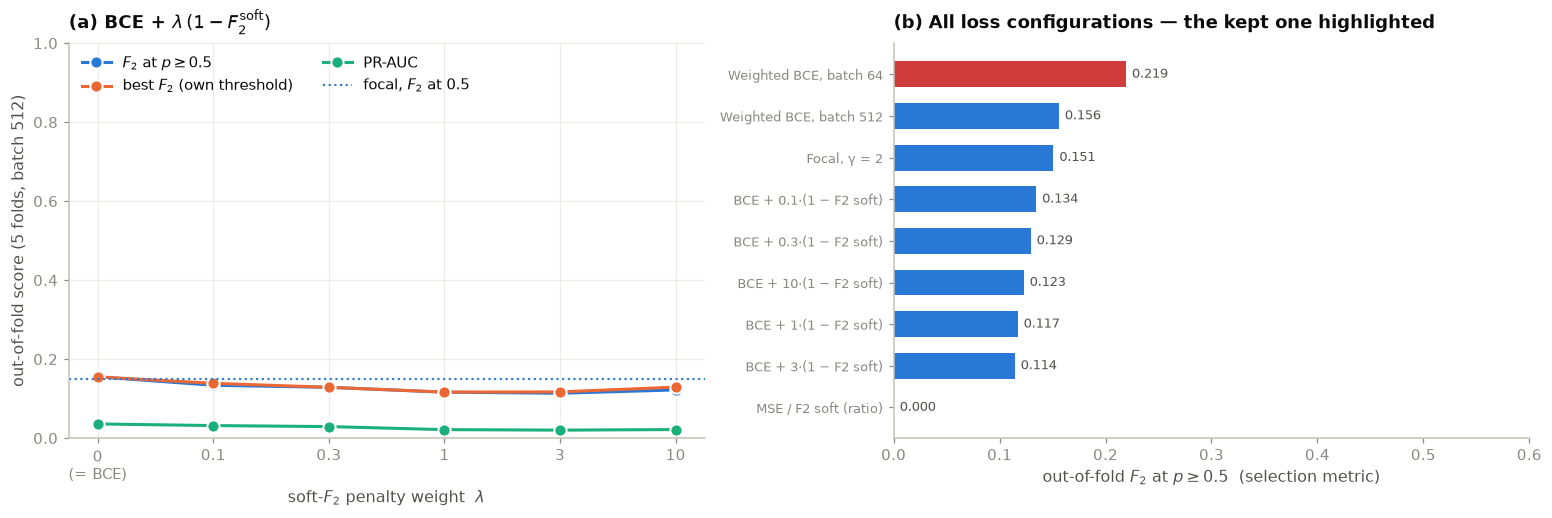

training loss kept for the rest of the notebook: Weighted BCE, batch 64
                   loss   pr_auc  roc_auc  f2_at_0.5  recall_at_0.5  precision_at_0.5  best_f2  median_oof_proba
 Weighted BCE, batch 64 0.084498 0.806595   0.219156       0.482143          0.068878 0.233546          0.007463
Weighted BCE, batch 512 0.036536 0.766391   0.155844       0.428571          0.043956 0.155642          0.101664
BCE + 0.1·(1 − F2 soft) 0.032370 0.726602   0.134409       0.357143          0.038462 0.139442          0.086969
BCE + 0.3·(1 − F2 soft) 0.029806 0.729163   0.129252       0.339286          0.037182 0.129252          0.077303
  BCE + 1·(1 − F2 soft) 0.022086 0.687404   0.116959       0.285714          0.034783 0.117130          0.044858
  BCE + 3·(1 − F2 soft) 0.020854 0.685594   0.114192       0.250000          0.035990 0.117647          0.015108
 BCE + 10·(1 − F2 soft) 0.022259 0.698454   0.122642       0.232143          0.042484 0.129702          0.023461
           Focal, γ = 2 

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

# (a) the lambda sweep, with the two reference losses as horizontal guides
sweep = loss_results[loss_results["loss_name"] == "bce_soft_f2"].sort_values("f2_lambda")
xpos = np.arange(len(sweep))
ax = axes[0]
for k, (col, lbl) in enumerate([("f2_at_0.5", r"$F_2$ at $p \geq 0.5$"),
                                ("best_f2", r"best $F_2$ (own threshold)"),
                                ("pr_auc", "PR-AUC")]):
    ax.plot(xpos, sweep[col], marker="o", markersize=8, color=ps.SERIES[k], label=lbl,
            markeredgecolor="white", markeredgewidth=1.3)
focal = loss_results[loss_results["loss_name"] == "focal"].iloc[0]
ax.axhline(focal["f2_at_0.5"], color=ps.SERIES[0], linestyle=":", linewidth=1.4,
           label=r"focal, $F_2$ at 0.5")
ax.set_xticks(xpos, ["0\n(= BCE)"] + [f"{l:g}" for l in sweep["f2_lambda"].iloc[1:]])
ax.set_xlabel(r"soft-$F_2$ penalty weight  $\lambda$")
ax.set_ylabel("out-of-fold score (5 folds, batch 512)")
ax.set_title(r"(a) BCE + $\lambda\,(1 - F_2^{\mathrm{soft}})$")
ax.set_ylim(0, 1.0)
ax.legend(loc="upper left", ncols=2)
ax.grid(True, alpha=0.6)

# (b) every configuration, ranked by the selection metric
ax = axes[1]
ranked = loss_results.sort_values("f2_at_0.5")
best_label = BEST_LOSS_LABEL
colors = [ps.STATUS["critical"] if l == best_label else ps.SERIES[0] for l in ranked["loss"]]
bars = ax.barh(ranked["loss"], ranked["f2_at_0.5"], color=colors, height=0.62)
ax.bar_label(bars, fmt="{:.3f}".format, fontsize=8.5, color=ps.INK_SECONDARY, padding=4)
ax.set_xlabel(r"out-of-fold $F_2$ at $p \geq 0.5$  (selection metric)")
ax.set_xlim(0, max(0.6, ranked["f2_at_0.5"].max() * 1.3))
ax.set_title("(b) All loss configurations — the kept one highlighted")
ax.tick_params(axis="y", labelsize=8.5)
ps.grid_x_only(ax)

ps.save_fig(fig, "04_loss_comparison", RESULTS_DIR)
plt.show()

print(f"training loss kept for the rest of the notebook: {BEST_LOSS_LABEL}")
print(loss_results[["loss", "pr_auc", "roc_auc", "f2_at_0.5", "recall_at_0.5",
                    "precision_at_0.5", "best_f2", "median_oof_proba"]].to_string(index=False))

Two things to read off the table. First, compare the two weighted-BCE rows:
the change from batch 64 to 512 is itself an effect, separate from the loss.
Second, `median_oof_proba` shows where each loss puts its probability mass —
the ratio loss and large-$\lambda$ penalties pull the scale away from the 0.5
anchor, which is why they look poor at $p \ge 0.5$ but better at their own
best threshold. Since every alternative sits within one fold-to-fold standard
deviation of weighted BCE, weighted BCE is kept for the rest of the notebook:
it is the proper scoring rule of the set, and the recall/precision trade-off
is made explicitly at the threshold in §7 rather than baked into the loss.

## 5. Network architecture

Four shapes, each with the activation and initialiser selected in §3 and all
other settings fixed. Alongside the CV scores we record the operational
quantities: how many high-risk events are missed, how many analyst reviews are
generated, and what it costs to train.

In [11]:
ARCHITECTURES = {
    "Single wide [200]": (200,),
    "Two equal [100, 100]": (100, 100),
    "Decreasing [128, 64, 32]": (128, 64, 32),
    "Increasing [32, 64, 128]": (32, 64, 128),
}

arch_rows = []
for label, hidden in ARCHITECTURES.items():
    est = base_clf(hidden_dims=hidden, activation=BEST_ACTIVATION, initialization=BEST_INIT)
    res, _ = run_grid(est, {"hidden_dims": [hidden]}, X_dev, y_dev)
    row = res.iloc[0].to_dict()

    # Out-of-fold predictions give the confusion counts that `GridSearchCV`
    # scores do not expose, using exactly the same folds.
    oof = cross_val_predict(est, X_dev, y_dev, cv=CV, method="predict_proba", n_jobs=N_JOBS)[:, 1]
    pred = (oof >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_dev, pred).ravel()

    n_params = fc.count_parameters(
        fc.FFNN(N_FEATURES, hidden, BEST_ACTIVATION, BEST_INIT, 1)
    )
    arch_rows.append({
        "architecture": label, "hidden": str(list(hidden)), "parameters": n_params,
        "f2": row["f2"], "std_f2": row["std_f2"],
        "recall": row["recall"], "precision": row["precision"],
        "pr_auc": row["pr_auc"], "roc_auc": row["roc_auc"],
        "false_negatives": int(fn), "false_positives": int(fp),
        "pct_flagged": 100 * pred.mean(),
        "fit_time_s": row["mean_fit_time"],
    })

arch_results = pd.DataFrame(arch_rows)
ps.save_table(arch_results, "05_architectures", RESULTS_DIR)
print(arch_results.to_string(index=False))

  1 configs x 5 folds in 15 s (best f2 = 0.166)


  1 configs x 5 folds in 11 s (best f2 = 0.226)


  1 configs x 5 folds in 15 s (best f2 = 0.185)


  1 configs x 5 folds in 14 s (best f2 = 0.110)


  saved ../results/classification/tables/05_architectures.csv
            architecture        hidden  parameters       f2   std_f2   recall  precision   pr_auc  roc_auc  false_negatives  false_positives  pct_flagged  fit_time_s
       Single wide [200]         [200]       47001 0.166457 0.103219 0.395455   0.082079 0.107641 0.888217               34              458     6.809477    6.846541
    Two equal [100, 100]    [100, 100]       33601 0.225717 0.051228 0.486364   0.106565 0.116328 0.887012               29              365     5.561072    4.536276
Decreasing [128, 64, 32] [128, 64, 32]       40321 0.184912 0.113084 0.395455   0.107232 0.117416 0.895202               34              464     6.894595    6.998540
Increasing [32, 64, 128] [32, 64, 128]       18049 0.109786 0.092079 0.251515   0.070929 0.105167 0.893486               42              213     3.220315    6.432677


  saved ../results/classification/figures/05_architectures.png


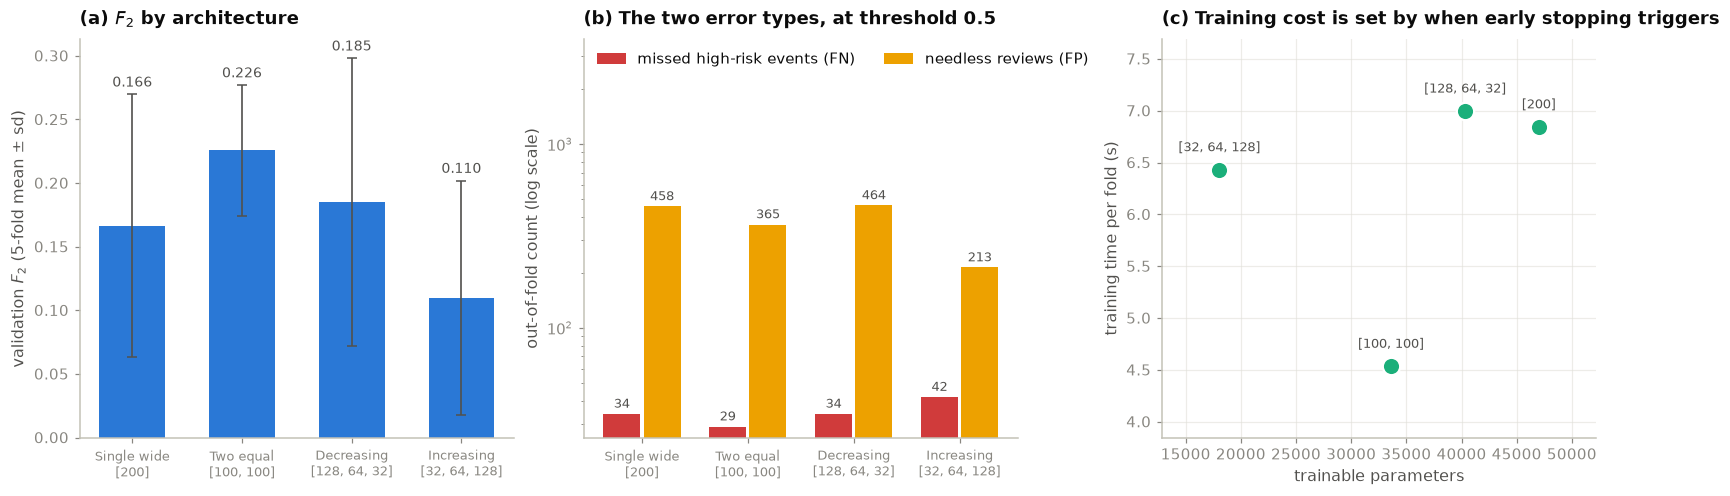

selected architecture: Two equal [100, 100] -> hidden_dims = [100, 100]


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.4))
labels = [a.replace(" [", "\n[") for a in arch_results["architecture"]]

# Colour carries nothing here — the x-axis already names each architecture.
ax = axes[0]
bars = ax.bar(labels, arch_results["f2"], color=ps.SERIES[0], width=0.6,
              yerr=arch_results["std_f2"], capsize=3,
              error_kw=dict(ecolor=ps.INK_SECONDARY, lw=1.1))
ax.bar_label(bars, fmt="{:.3f}".format, fontsize=9, color=ps.INK_SECONDARY, padding=3)
ax.set_ylabel(r"validation $F_2$ (5-fold mean $\pm$ sd)")
ax.set_title(r"(a) $F_2$ by architecture")
ax.tick_params(axis="x", labelsize=8.5)
ps.grid_y_only(ax)

ax = axes[1]
x = np.arange(len(arch_results))
w = 0.38
b1 = ax.bar(x - w / 2, arch_results["false_negatives"], w * 0.92,
            color=ps.STATUS["critical"], label="missed high-risk events (FN)")
b2 = ax.bar(x + w / 2, arch_results["false_positives"], w * 0.92,
            color=ps.SERIES[3], label="needless reviews (FP)")
ax.bar_label(b1, fmt="%d", fontsize=8.5, color=ps.INK_SECONDARY, padding=2)
ax.bar_label(b2, fmt="%d", fontsize=8.5, color=ps.INK_SECONDARY, padding=2)
ax.set_xticks(x, labels, fontsize=8.5)
ax.set_yscale("log")
ax.set_ylim(top=max(arch_results["false_positives"].max(), 10) * 8)   # headroom for the legend
ax.set_ylabel("out-of-fold count (log scale)")
ax.set_title("(b) The two error types, at threshold 0.5")
ax.legend(loc="upper left", ncols=2)
ps.grid_y_only(ax)

ax = axes[2]
ax.scatter(arch_results["parameters"], arch_results["fit_time_s"],
           s=130, color=ps.SERIES[2], edgecolors="white", linewidths=1.5, zorder=3)
for _, r in arch_results.iterrows():
    ax.annotate(r["hidden"], (r["parameters"], r["fit_time_s"]),
                textcoords="offset points", xytext=(0, 12), ha="center",
                fontsize=8.5, color=ps.INK_SECONDARY)
ax.margins(x=0.18, y=0.28)      # keep the annotations inside the axes
ax.set_xlabel("trainable parameters")
ax.set_ylabel("training time per fold (s)")
ax.set_title("(c) Training cost is set by when early stopping triggers")
ax.grid(True, alpha=0.6)

ps.save_fig(fig, "05_architectures", RESULTS_DIR)
plt.show()

BEST_ARCH_LABEL = arch_results.sort_values("f2", ascending=False).iloc[0]["architecture"]
BEST_HIDDEN = ARCHITECTURES[BEST_ARCH_LABEL]
print(f"selected architecture: {BEST_ARCH_LABEL} -> hidden_dims = {list(BEST_HIDDEN)}")

## 6. Learning rate and weight decay

With the activation, initialiser and architecture fixed, `GridSearchCV` sweeps
the AdamW learning rate against the L2 weight decay — 16 combinations, 5 folds
each. Weight decay is applied to the weight matrices only; the biases sit in a
separate parameter group with `weight_decay=0`, matching the theory, where the
penalty sums over $W$ alone.

In [13]:
LEARNING_RATES = [1e-4, 3e-4, 1e-3, 3e-3]
WEIGHT_DECAYS = [0.0, 1e-5, 1e-4, 1e-3]

hp_results, hp_search = run_grid(
    base_clf(hidden_dims=BEST_HIDDEN, activation=BEST_ACTIVATION, initialization=BEST_INIT),
    {"lr": LEARNING_RATES, "weight_decay": WEIGHT_DECAYS},
    X_dev, y_dev,
)
ps.save_table(hp_results, "06_lr_weight_decay", RESULTS_DIR)
print(hp_results[["lr", "weight_decay", "f2", "std_f2", "pr_auc", "recall"]].head(8).to_string(index=False))

  16 configs x 5 folds in 198 s (best f2 = 0.236)
  saved ../results/classification/tables/06_lr_weight_decay.csv
    lr  weight_decay       f2   std_f2   pr_auc   recall
0.0010       0.00100 0.235865 0.060081 0.114452 0.503030
0.0010       0.00010 0.225717 0.051228 0.116328 0.486364
0.0010       0.00000 0.225717 0.051228 0.116328 0.486364
0.0010       0.00001 0.225717 0.051228 0.116328 0.486364
0.0001       0.00100 0.182896 0.070011 0.099110 0.322727
0.0001       0.00000 0.182890 0.070302 0.096287 0.322727
0.0001       0.00001 0.182890 0.070302 0.096287 0.322727
0.0001       0.00010 0.182890 0.070302 0.096287 0.322727


  saved ../results/classification/figures/06_lr_weight_decay_heatmap.png


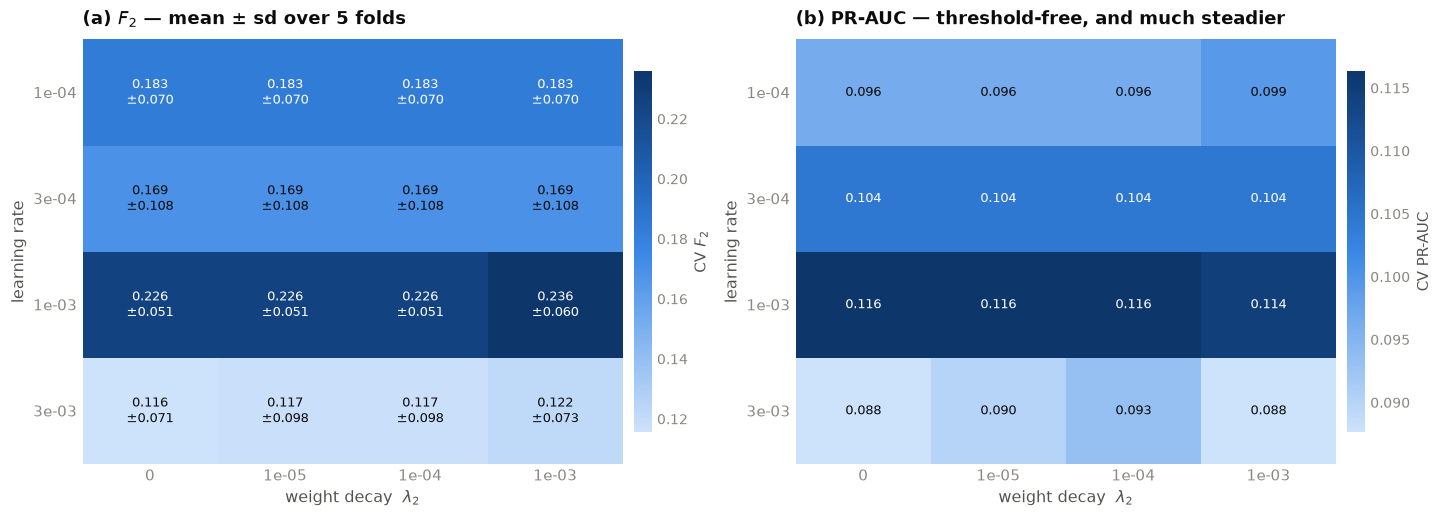

selected: lr = 0.001, weight_decay = 0.001


In [14]:
def pivot_grid(df, value, rows, cols, row_key, col_key):
    """Reshape a flat CV table into a (len(rows), len(cols)) array."""
    out = np.full((len(rows), len(cols)), np.nan)
    for i, r in enumerate(rows):
        for j, c in enumerate(cols):
            m = df[(df[row_key].astype(float) == r) & (df[col_key].astype(float) == c)]
            if len(m):
                out[i, j] = float(m[value].iloc[0])
    return out


F2_GRID = pivot_grid(hp_results, "f2", LEARNING_RATES, WEIGHT_DECAYS, "lr", "weight_decay")
SD_GRID = pivot_grid(hp_results, "std_f2", LEARNING_RATES, WEIGHT_DECAYS, "lr", "weight_decay")
AP_GRID = pivot_grid(hp_results, "pr_auc", LEARNING_RATES, WEIGHT_DECAYS, "lr", "weight_decay")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
wd_labels = ["0" if w == 0 else f"{w:.0e}" for w in WEIGHT_DECAYS]
lr_labels = [f"{l:.0e}" for l in LEARNING_RATES]

# Sequential single-hue ramp: this encodes magnitude, not identity.
ps.heatmap(axes[0], F2_GRID, wd_labels, lr_labels, errors=SD_GRID,
           cbar_label=r"CV $F_2$")
axes[0].set_xlabel(r"weight decay  $\lambda_2$")
axes[0].set_ylabel("learning rate")
axes[0].set_title(r"(a) $F_2$ — mean $\pm$ sd over 5 folds")

ps.heatmap(axes[1], AP_GRID, wd_labels, lr_labels, cbar_label="CV PR-AUC")
axes[1].set_xlabel(r"weight decay  $\lambda_2$")
axes[1].set_ylabel("learning rate")
axes[1].set_title("(b) PR-AUC — threshold-free, and much steadier")

ps.save_fig(fig, "06_lr_weight_decay_heatmap", RESULTS_DIR)
plt.show()

BEST_LR = float(hp_results.iloc[0]["lr"])
BEST_WD = float(hp_results.iloc[0]["weight_decay"])
print(f"selected: lr = {BEST_LR:g}, weight_decay = {BEST_WD:g}")

The learning rate dominates; weight decay barely moves either metric. With 125
inputs, ~56 positives and early stopping already in place, the network is
regularised mostly by *when training stops*, so an explicit L2 penalty has
little left to do — the same conclusion the Project 2 MNIST cross-validation
reached, where the optimal ridge parameter also came out at zero.

## 7. Choosing the decision threshold

Classifying at $p \ge 0.5$ is an arbitrary choice, and a poor one when the
positive class is under 1 %. The threshold is a free parameter of the
*decision rule*, not of the model, and it is selected here from **out-of-fold**
predictions on the development set — each event scored by a model that never
saw it — and then **frozen** before the test set is opened.

Two candidate rules:

1. **Max-$F_2$** — the threshold maximising $F_2$ out of fold.
2. **95 % recall** — the highest threshold that still catches 95 % of high-risk
   events, i.e. the cheapest rule meeting a safety requirement.

In [15]:
final_estimator = base_clf(
    hidden_dims=BEST_HIDDEN, activation=BEST_ACTIVATION,
    initialization=BEST_INIT, lr=BEST_LR, weight_decay=BEST_WD,
)
oof_proba, fold_models, fold_fit_time = cv_ensemble(final_estimator, X_dev, y_dev)
print(f"out-of-fold PR-AUC {average_precision_score(y_dev, oof_proba):.3f} | "
      f"ROC-AUC {roc_auc_score(y_dev, oof_proba):.3f}")

grid = np.unique(np.concatenate([[0.0], np.quantile(oof_proba, np.linspace(0, 1, 801)), [1.0]]))
rows = []
for thr in grid:
    pred = (oof_proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_dev, pred, labels=[0, 1]).ravel()
    rows.append({
        "threshold": thr,
        "f2": fbeta_score(y_dev, pred, beta=2, zero_division=0),
        "recall": recall_score(y_dev, pred, zero_division=0),
        "precision": precision_score(y_dev, pred, zero_division=0),
        "false_negatives": int(fn), "false_positives": int(fp),
        "frac_reviewed": pred.mean(),
    })
thr_df = pd.DataFrame(rows)
ps.save_table(thr_df, "07_threshold_sweep", RESULTS_DIR)

THR_MAX_F2 = float(thr_df.loc[thr_df["f2"].idxmax(), "threshold"])
meets = thr_df[thr_df["recall"] >= 0.95]
THR_95_RECALL = float(meets.loc[meets["frac_reviewed"].idxmin(), "threshold"]) if len(meets) else 0.0

# Out of fold, a few high-risk events receive probabilities close to zero, so
# 95 % recall may only be reachable by reviewing (almost) every event. Record
# whether that is the case, because it changes how the rule should be read.
row_95_tmp = thr_df.iloc[(thr_df["threshold"] - THR_95_RECALL).abs().idxmin()]
RECALL_95_REACHABLE = bool(row_95_tmp["frac_reviewed"] < 0.5)
max_recall_below_half = thr_df[thr_df["frac_reviewed"] <= 0.5]["recall"].max()
print(f"highest out-of-fold recall while reviewing <= 50 % of events: {max_recall_below_half:.1%}")
if not RECALL_95_REACHABLE:
    print("95 % recall is NOT reachable without reviewing essentially every event; "
          "the rule degenerates to 'flag everything' and is reported as such.")

row_f2 = thr_df.iloc[(thr_df["threshold"] - THR_MAX_F2).abs().idxmin()]
row_95 = thr_df.iloc[(thr_df["threshold"] - THR_95_RECALL).abs().idxmin()]
thr_summary = pd.DataFrame([
    {"rule": "max F2", **row_f2.to_dict()},
    {"rule": "95% recall", **row_95.to_dict()},
])
ps.save_table(thr_summary, "07_threshold_rules", RESULTS_DIR)
print(thr_summary.to_string(index=False))

# `max F2` is the primary operating threshold: F2 is the stated selection
# metric, and the 95%-recall rule is reported alongside as the safety-first
# alternative. Frozen here, before the test set is touched.
PRIMARY_THRESHOLD = THR_MAX_F2
print(f"\nFROZEN primary threshold = {PRIMARY_THRESHOLD:.4f} (max-F2 rule)")
print(f"       alternative        = {THR_95_RECALL:.4f} (95%-recall rule"
      f"{'' if RECALL_95_REACHABLE else ' -- degenerate, flags everything'})")

out-of-fold PR-AUC 0.091 | ROC-AUC 0.813


  saved ../results/classification/tables/07_threshold_sweep.csv
highest out-of-fold recall while reviewing <= 50 % of events: 87.5%
95 % recall is NOT reachable without reviewing essentially every event; the rule degenerates to 'flag everything' and is reported as such.
  saved ../results/classification/tables/07_threshold_rules.csv
      rule  threshold       f2   recall  precision  false_negatives  false_positives  frac_reviewed
    max F2   0.580761 0.239583 0.410714   0.089844             33.0            233.0       0.036317
95% recall   0.000029 0.043076 0.964286   0.008934              2.0           5990.0       0.857427

FROZEN primary threshold = 0.5808 (max-F2 rule)
       alternative        = 0.0000 (95%-recall rule -- degenerate, flags everything)


  saved ../results/classification/figures/07_threshold_selection.png


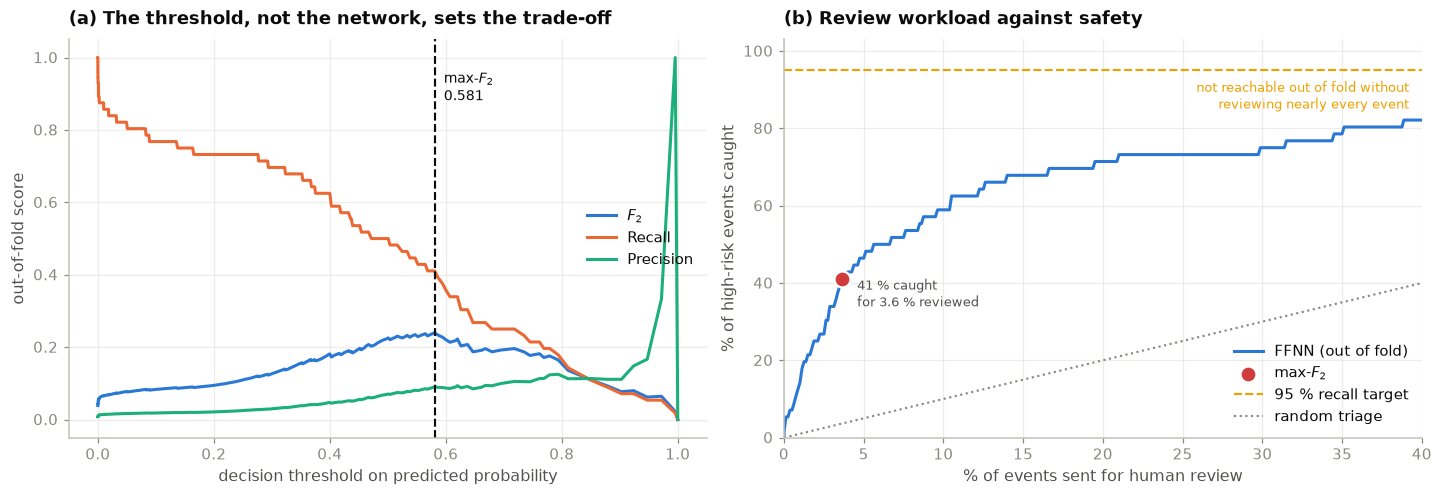

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

ax = axes[0]
ax.plot(thr_df["threshold"], thr_df["f2"], color=ps.SERIES[0], label=r"$F_2$")
ax.plot(thr_df["threshold"], thr_df["recall"], color=ps.SERIES[1], label="Recall")
ax.plot(thr_df["threshold"], thr_df["precision"], color=ps.SERIES[2], label="Precision")
ax.axvline(PRIMARY_THRESHOLD, color=ps.INK, linestyle="--", linewidth=1.4)
ax.annotate(f"max-$F_2$\n{PRIMARY_THRESHOLD:.3f}", xy=(PRIMARY_THRESHOLD, 0.92),
            xycoords=("data", "axes fraction"), xytext=(6, 0), textcoords="offset points",
            fontsize=9, color=ps.INK, va="top")
ax.set_xlabel("decision threshold on predicted probability")
ax.set_ylabel("out-of-fold score")
ax.set_title("(a) The threshold, not the network, sets the trade-off")
ax.legend(loc="center right")
ax.grid(True, alpha=0.6)

# Operational view: what fraction of events must a human look at to catch what
# fraction of the real high-risk ones?
ax = axes[1]
ax.plot(100 * thr_df["frac_reviewed"], 100 * thr_df["recall"],
        color=ps.SERIES[0], label="FFNN (out of fold)")
markers = [(PRIMARY_THRESHOLD, r"max-$F_2$", ps.STATUS["critical"], "o")]
if RECALL_95_REACHABLE:
    markers.append((THR_95_RECALL, "95 % recall", ps.SERIES[3], "s"))
for thr, name, colour, marker in markers:
    r = thr_df.iloc[(thr_df["threshold"] - thr).abs().idxmin()]
    ax.scatter(100 * r["frac_reviewed"], 100 * r["recall"], s=110, color=colour,
               edgecolors="white", linewidths=1.5, zorder=4, marker=marker, label=name)
    ax.annotate(f"{100 * r['recall']:.0f} % caught\nfor {100 * r['frac_reviewed']:.1f} % reviewed",
                xy=(100 * r["frac_reviewed"], 100 * r["recall"]),
                textcoords="offset points", xytext=(10, -18), fontsize=8.5,
                color=ps.INK_SECONDARY)
if not RECALL_95_REACHABLE:
    ax.axhline(95, color=ps.SERIES[3], linestyle="--", linewidth=1.4, label="95 % recall target")
    ax.annotate("not reachable out of fold without\nreviewing nearly every event",
                xy=(0.98, 95), xycoords=("axes fraction", "data"), xytext=(0, -6),
                textcoords="offset points", ha="right", va="top", fontsize=8.5,
                color=ps.SERIES[3])
# A random triage rule reviews x % of events and catches x % of positives.
ax.plot([0, 100], [0, 100], color=ps.INK_MUTED, linestyle=":", linewidth=1.4,
        label="random triage")
ax.set_xlim(0, max(40, 100 * row_95["frac_reviewed"] + 10) if RECALL_95_REACHABLE else 40)
ax.set_ylim(0, 103)
ax.set_xlabel("% of events sent for human review")
ax.set_ylabel("% of high-risk events caught")
ax.set_title("(b) Review workload against safety")
ax.legend(loc="lower right")
ax.grid(True, alpha=0.6)

ps.save_fig(fig, "07_threshold_selection", RESULTS_DIR)
plt.show()

## 8. Ablation — how much of this is just the current risk estimate?

§2(b) showed that the risk value in the last pre-cutoff CDM already separates
the classes. Here the whole shared pipeline is rebuilt with
`include_current_risk=False`, which removes `risk`, `max_risk_estimate` and
`max_risk_scaling` from the pass-through block (they never enter the PCA),
leaving only orbital geometry, covariance, timing and object metadata.

Neither setting is leakage: both use information available two days before TCA.
They answer different questions.

  1 configs x 5 folds in 11 s (best f2 = 0.236)


  1 configs x 5 folds in 13 s (best f2 = 0.059)
  saved ../results/classification/tables/08_risk_ablation.csv
 current risk in features  features       f2   std_f2   recall  precision   pr_auc  std_pr_auc  roc_auc
                     True       233 0.235865 0.060081 0.503030   0.100683 0.114452    0.071880 0.886378
                    False       221 0.058555 0.058419 0.106061   0.035952 0.047972    0.042094 0.764588


  saved ../results/classification/figures/08_risk_ablation.png


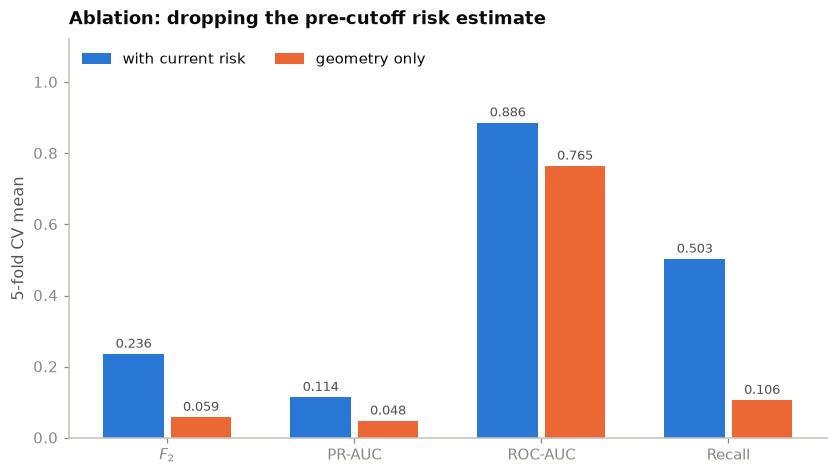

In [17]:
abl_rows = []
for include_risk in (True, False):
    sh = shared if include_risk else rd.build_shared_datasets(
        variance_threshold=VARIANCE_THRESHOLD, include_current_risk=False,
        val_size=VAL_SIZE, test_size=TEST_SIZE, seed=SEED, verbose=False)
    sc = StandardScaler().fit(sh["aggregate"]["train"])
    Xd = np.vstack([sc.transform(sh["aggregate"]["train"]),
                    sc.transform(sh["aggregate"]["val"])]).astype(np.float32)
    yd = np.concatenate([sh["y_class"]["train"], sh["y_class"]["val"]])
    res, _ = run_grid(
        base_clf(hidden_dims=BEST_HIDDEN, activation=BEST_ACTIVATION,
                 initialization=BEST_INIT, lr=BEST_LR, weight_decay=BEST_WD),
        {"hidden_dims": [BEST_HIDDEN]}, Xd, yd,
    )
    r = res.iloc[0]
    abl_rows.append({
        "current risk in features": include_risk,
        "features": Xd.shape[1],
        "f2": r["f2"], "std_f2": r["std_f2"],
        "recall": r["recall"], "precision": r["precision"],
        "pr_auc": r["pr_auc"], "std_pr_auc": r["std_pr_auc"], "roc_auc": r["roc_auc"],
    })

ablation = pd.DataFrame(abl_rows)
ps.save_table(ablation, "08_risk_ablation", RESULTS_DIR)
print(ablation.to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
mets = ["f2", "pr_auc", "roc_auc", "recall"]
mlabels = [r"$F_2$", "PR-AUC", "ROC-AUC", "Recall"]
x = np.arange(len(mets))
w = 0.36
for k, inc in enumerate([True, False]):
    r = ablation[ablation["current risk in features"] == inc].iloc[0]
    bars = ax.bar(x + (k - 0.5) * w, [r[m] for m in mets], w * 0.9, color=ps.SERIES[k],
                  label="with current risk" if inc else "geometry only")
    ax.bar_label(bars, fmt="{:.3f}".format, fontsize=8.5, color=ps.INK_SECONDARY, padding=2)
ax.set_xticks(x, mlabels)
ax.set_ylabel("5-fold CV mean")
ax.set_ylim(0, 1.12)
ax.set_title("Ablation: dropping the pre-cutoff risk estimate")
ax.legend(ncols=2, loc="upper left")
ps.grid_y_only(ax)
ps.save_fig(fig, "08_risk_ablation", RESULTS_DIR)
plt.show()

## 9. Learning curves of the selected model

A single fit on the 70 % training split, monitored on the 15 % validation
split, to show what one training run actually does. Early stopping watches
validation PR-AUC and the best state is restored, so the curves continue past
the chosen epoch only to show what would have happened.

In [18]:
fc.set_seed(SEED)
pw = float((len(y_train) - y_train.sum()) / y_train.sum())
curve_model = fc.FFNN(N_FEATURES, BEST_HIDDEN, BEST_ACTIVATION, BEST_INIT, 1)
lk = {"loss_name": "bce", "f2_lambda": 0.0, "focal_gamma": 2.0, "batch_size": BATCH_SIZE}
lk.update(LOSS_OVERRIDES)
curve_model, history = fc.train_model(
    curve_model, X_train, y_train, X_val, y_val,
    task="classification", loss_name=lk["loss_name"], pos_weight=pw,
    f2_lambda=lk["f2_lambda"], focal_gamma=lk["focal_gamma"],
    lr=BEST_LR, weight_decay=BEST_WD, batch_size=lk["batch_size"],
    max_epochs=MAX_EPOCHS, patience=PATIENCE, grad_clip=GRAD_CLIP, device=DEVICE,
)
hist_df = pd.DataFrame({k: history[k] for k in
                        ("train_loss", "val_loss", "val_score", "epoch_time", "cum_time")})
hist_df.insert(0, "epoch", np.arange(1, len(hist_df) + 1))
ps.save_table(hist_df, "09_learning_curves", RESULTS_DIR)
print(f"stopped after {history['n_epochs']} epochs; best epoch {history['best_epoch']}; "
      f"{history['total_time']:.1f} s; {fc.count_parameters(curve_model)} parameters")

  saved ../results/classification/tables/09_learning_curves.csv
stopped after 33 epochs; best epoch 13; 5.1 s; 33601 parameters


  saved ../results/classification/figures/09_learning_curves.png


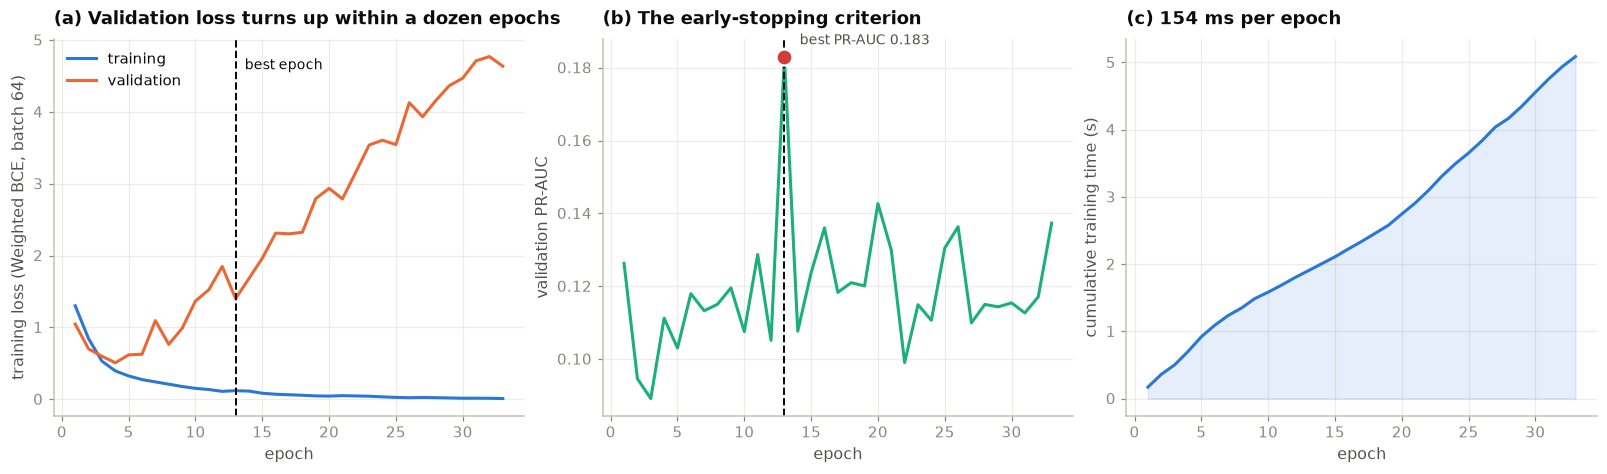

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.2))
epochs = hist_df["epoch"]

ax = axes[0]
ax.plot(epochs, hist_df["train_loss"], color=ps.SERIES[0], label="training")
ax.plot(epochs, hist_df["val_loss"], color=ps.SERIES[1], label="validation")
ax.axvline(history["best_epoch"], color=ps.INK, linestyle="--", linewidth=1.3)
ax.annotate("best epoch", xy=(history["best_epoch"], 0.95),
            xycoords=("data", "axes fraction"), xytext=(6, 0),
            textcoords="offset points", fontsize=9, color=ps.INK, va="top")
ax.set_xlabel("epoch")
ax.set_ylabel(f"training loss ({BEST_LOSS_LABEL})")
ax.set_title("(a) Validation loss turns up within a dozen epochs")
ax.legend()
ax.grid(True, alpha=0.6)

ax = axes[1]
ax.plot(epochs, hist_df["val_score"], color=ps.SERIES[2])
ax.axvline(history["best_epoch"], color=ps.INK, linestyle="--", linewidth=1.3)
ax.scatter([history["best_epoch"]], [history["best_score"]], s=110,
           color=ps.STATUS["critical"], edgecolors="white", linewidths=1.5, zorder=4)
ax.annotate(f"best PR-AUC {history['best_score']:.3f}",
            xy=(history["best_epoch"], history["best_score"]),
            textcoords="offset points", xytext=(10, 8), fontsize=9, color=ps.INK_SECONDARY)
ax.set_xlabel("epoch")
ax.set_ylabel("validation PR-AUC")
ax.set_title("(b) The early-stopping criterion")
ax.grid(True, alpha=0.6)

ax = axes[2]
ax.plot(epochs, hist_df["cum_time"], color=ps.SERIES[0])
ax.fill_between(epochs, 0, hist_df["cum_time"], color=ps.SERIES[0], alpha=0.12)
ax.set_xlabel("epoch")
ax.set_ylabel("cumulative training time (s)")
ax.set_title(f"(c) {hist_df['epoch_time'].mean() * 1000:.0f} ms per epoch")
ax.grid(True, alpha=0.6)

ps.save_fig(fig, "09_learning_curves", RESULTS_DIR)
plt.show()

Validation loss bottoms out within about ten epochs and then climbs steadily,
while PR-AUC jumps around from epoch to epoch — with only 10 positives in the
validation split, a single event changing rank moves it by several points.
With 46 positives in the training split the network memorises them quickly;
early stopping is doing nearly all of the regularising, which is exactly why
§6 found weight decay to be inert.

## 10. Final evaluation on the held-out test set

Everything above used only the development set. The final predictor is the
**average of the five fold models from §7** — the models whose out-of-fold
predictions the threshold was tuned on — evaluated once on the 1 244 test
events with the threshold frozen in §7.

A single network refitted on all development data is also scored, to show why
the ensemble is used: with early stopping, a refit stops at a different epoch
and its probabilities land on a different scale, so a threshold chosen out of
fold no longer means the same thing (compare the "fraction flagged" line).

In [20]:
# (i) The CV ensemble: the five fold models from §7, averaged. These are the
#     models whose out-of-fold predictions the threshold was tuned on.
test_proba = ensemble_proba(fold_models, X_test)
final_train_time = fold_fit_time

# (ii) For comparison, one model refitted on the whole development set.
fc.set_seed(SEED)
refit_model = base_clf(hidden_dims=BEST_HIDDEN, activation=BEST_ACTIVATION,
                       initialization=BEST_INIT, lr=BEST_LR, weight_decay=BEST_WD)
t0 = time.perf_counter()
refit_model.fit(X_dev, y_dev)
refit_train_time = time.perf_counter() - t0
test_proba_refit = refit_model.predict_proba(X_test)[:, 1]


def classification_report_row(name, y_true, proba, threshold, train_time=np.nan):
    """Every metric the report needs, for one model at one threshold."""
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "model": name,
        "threshold": threshold,
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": fbeta_score(y_true, pred, beta=1, zero_division=0),
        "f2": fbeta_score(y_true, pred, beta=2, zero_division=0),
        "pr_auc": average_precision_score(y_true, proba),
        "roc_auc": roc_auc_score(y_true, proba),
        "true_positives": int(tp), "false_negatives": int(fn),
        "false_positives": int(fp), "true_negatives": int(tn),
        "frac_reviewed": pred.mean(),
        "train_time_s": train_time,
    }


final_rows = [
    classification_report_row(f"FFNN CV-ensemble @ max-F2 ({PRIMARY_THRESHOLD:.3f})",
                              y_test, test_proba, PRIMARY_THRESHOLD, final_train_time),
    classification_report_row(f"FFNN CV-ensemble @ 95% recall ({THR_95_RECALL:.3f})",
                              y_test, test_proba, THR_95_RECALL, final_train_time),
    classification_report_row("FFNN CV-ensemble @ 0.5 (untuned)",
                              y_test, test_proba, 0.5, final_train_time),
    classification_report_row(f"FFNN refit on all dev @ max-F2 ({PRIMARY_THRESHOLD:.3f})",
                              y_test, test_proba_refit, PRIMARY_THRESHOLD, refit_train_time),
]
final_results = pd.DataFrame(final_rows)
ps.save_table(final_results, "10_final_test_results", RESULTS_DIR)
print(final_results.drop(columns=["train_time_s"]).to_string(index=False))

print(f"\nfraction of test events flagged at p >= {PRIMARY_THRESHOLD:.3f}: "
      f"ensemble {np.mean(test_proba >= PRIMARY_THRESHOLD):.1%} vs "
      f"refit {np.mean(test_proba_refit >= PRIMARY_THRESHOLD):.1%} "
      f"(out of fold it was {row_f2['frac_reviewed']:.1%})")

# Accuracy is reported once, only to show why it is useless here.
acc = ((test_proba >= PRIMARY_THRESHOLD).astype(int) == y_test).mean()
print(f"\n(accuracy at the primary threshold: {acc:.4f}; always predicting "
      f"'low risk' scores {1 - y_test.mean():.4f} — this is why accuracy is not used)")

  saved ../results/classification/tables/10_final_test_results.csv
                                 model  threshold  precision  recall       f1       f2   pr_auc  roc_auc  true_positives  false_negatives  false_positives  true_negatives  frac_reviewed
     FFNN CV-ensemble @ max-F2 (0.581)   0.580761   0.055556     0.2 0.086957 0.131579 0.156747 0.929335               2                8               34            1200       0.028939
 FFNN CV-ensemble @ 95% recall (0.000)   0.000029   0.008039     1.0 0.015949 0.038941 0.156747 0.929335              10                0             1234               0       1.000000
      FFNN CV-ensemble @ 0.5 (untuned)   0.500000   0.049180     0.3 0.084507 0.148515 0.156747 0.929335               3                7               58            1176       0.049035
FFNN refit on all dev @ max-F2 (0.581)   0.580761   0.071429     0.7 0.129630 0.253623 0.161094 0.924473               7                3               91            1143       0.078778

fr

  saved ../results/classification/figures/10_final_test_curves.png


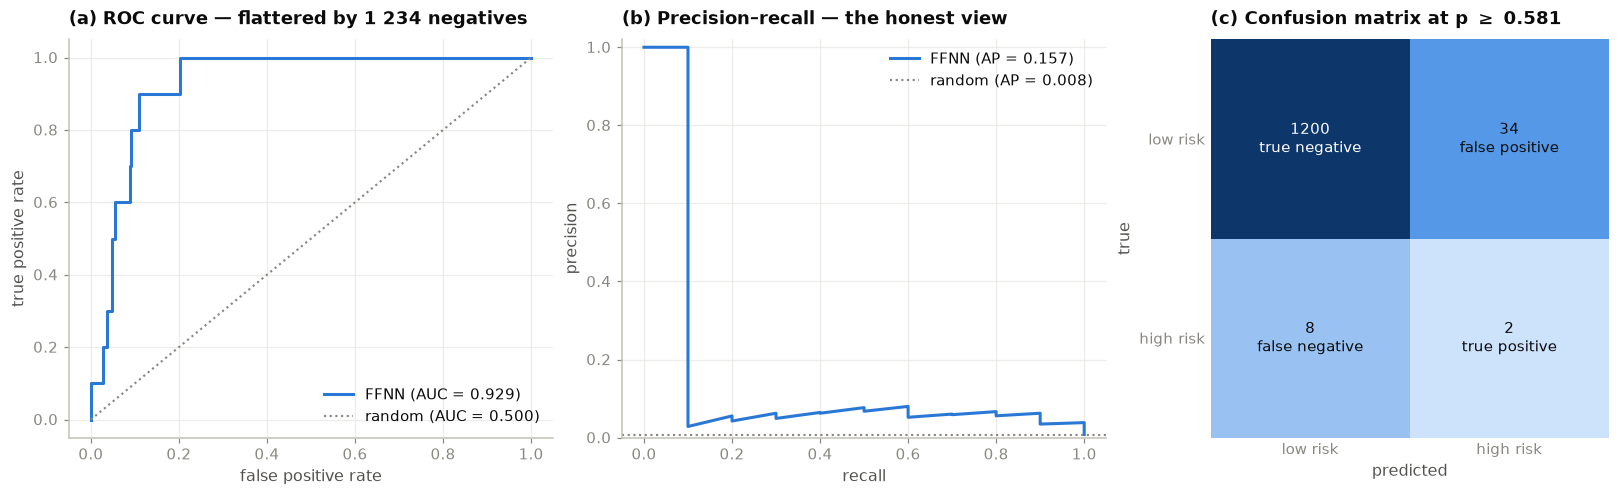

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

ax = axes[0]
fpr, tpr, _ = roc_curve(y_test, test_proba)
ax.plot(fpr, tpr, color=ps.SERIES[0],
        label=f"FFNN (AUC = {roc_auc_score(y_test, test_proba):.3f})")
ax.plot([0, 1], [0, 1], color=ps.INK_MUTED, linestyle=":", linewidth=1.4,
        label="random (AUC = 0.500)")
ax.set_xlabel("false positive rate")
ax.set_ylabel("true positive rate")
ax.set_title("(a) ROC curve — flattered by 1 234 negatives")
ax.legend(loc="lower right")
ax.grid(True, alpha=0.6)

ax = axes[1]
prec, rec, _ = precision_recall_curve(y_test, test_proba)
ax.plot(rec, prec, color=ps.SERIES[0],
        label=f"FFNN (AP = {average_precision_score(y_test, test_proba):.3f})")
ax.axhline(y_test.mean(), color=ps.INK_MUTED, linestyle=":", linewidth=1.4,
           label=f"random (AP = {y_test.mean():.3f})")
ax.set_xlabel("recall")
ax.set_ylabel("precision")
ax.set_ylim(0, 1.02)
ax.set_title("(b) Precision–recall — the honest view")
ax.legend(loc="upper right")
ax.grid(True, alpha=0.6)

ax = axes[2]
cm = confusion_matrix(y_test, (test_proba >= PRIMARY_THRESHOLD).astype(int), labels=[0, 1])
# log1p shading so the two tiny positive cells are not crushed by 1 200 TNs
im = ax.imshow(np.log1p(cm), cmap=ps.SEQ_CMAP)
ax.set_xticks([0, 1], ["low risk", "high risk"])
ax.set_yticks([0, 1], ["low risk", "high risk"])
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.grid(False)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
names = [["true negative", "false positive"], ["false negative", "true positive"]]
for i in range(2):
    for j in range(2):
        shade = im.norm(np.log1p(cm[i, j]))
        ax.text(j, i, f"{cm[i, j]}\n{names[i][j]}", ha="center", va="center",
                fontsize=10, color="#ffffff" if shade > 0.55 else ps.INK)
ax.set_title(f"(c) Confusion matrix at p $\\geq$ {PRIMARY_THRESHOLD:.3f}")

ps.save_fig(fig, "10_final_test_curves", RESULTS_DIR)
plt.show()

## 11. Benchmark against classical baselines

The FFNN is only interesting if it beats simpler things. Every baseline sees
exactly the same features, the same development set and the same frozen test
set, and each follows the same protocol as the FFNN — five fold models,
threshold tuned on their out-of-fold predictions, test prediction from their
average — so the comparison is like for like.

The most important baseline is not a learned model at all: **flag the event if
the risk already reported at the 2-day cutoff is at or above $-6$.** That rule
needs no training and is what an operator could do with a spreadsheet.

In [22]:
BASELINES = {
    "Always 'low risk'": DummyClassifier(strategy="constant", constant=0),
    "Logistic regression": LogisticRegression(max_iter=5000, class_weight="balanced"),
    "Random forest": RandomForestClassifier(n_estimators=400, class_weight="balanced_subsample",
                                            random_state=SEED, n_jobs=N_JOBS),
    "Gradient boosting": HistGradientBoostingClassifier(random_state=SEED),
}

bench_rows = []

# (i) the untrained operator rule, on the raw (unscaled) risk column
raw_risk_test = meta["test"]["last_risk"].values
bench_rows.append(classification_report_row(
    "Rule: current risk >= -6", y_test, raw_risk_test, rd.HIGH_RISK_THRESHOLD, 0.0))

# (ii) trained baselines — same protocol as the FFNN: 5 fold models, threshold
#      from their out-of-fold predictions, test prediction from their average.
for name, model in BASELINES.items():
    if name.startswith("Always"):
        model.fit(X_dev, y_dev)
        bench_rows.append(classification_report_row(
            name, y_test, model.predict_proba(X_test)[:, 1], 0.5, 0.0))
        continue
    oof, models, tt = cv_ensemble(model, X_dev, y_dev)
    thr, _ = best_f2_threshold(y_dev, oof)
    bench_rows.append(classification_report_row(
        name, y_test, ensemble_proba(models, X_test), thr, tt))

# (iii) the selected FFNN
bench_rows.append(classification_report_row(
    "FFNN (this notebook)", y_test, test_proba, PRIMARY_THRESHOLD, final_train_time))

benchmark = pd.DataFrame(bench_rows).sort_values("f2", ascending=False).reset_index(drop=True)
ps.save_table(benchmark, "11_benchmark", RESULTS_DIR)
print(benchmark[["model", "f2", "recall", "precision", "pr_auc", "roc_auc",
                 "false_negatives", "false_positives", "frac_reviewed",
                 "train_time_s"]].to_string(index=False))

  saved ../results/classification/tables/11_benchmark.csv
                   model       f2  recall  precision   pr_auc  roc_auc  false_negatives  false_positives  frac_reviewed  train_time_s
Rule: current risk >= -6 0.406977     0.7   0.152174 0.193588 0.959076                3               39       0.036977      0.000000
       Gradient boosting 0.370370     0.6   0.146341 0.153652 0.934441                4               35       0.032958     13.576129
           Random forest 0.353535     0.7   0.118644 0.270494 0.954741                3               52       0.047428     25.408923
     Logistic regression 0.187500     0.3   0.075000 0.111450 0.928687                7               37       0.032154      2.063130
    FFNN (this notebook) 0.131579     0.2   0.055556 0.156747 0.929335                8               34       0.028939     24.392479
       Always 'low risk' 0.000000     0.0   0.000000 0.008039 0.500000               10                0       0.000000      0.000000


  saved ../results/classification/figures/11_benchmark.png


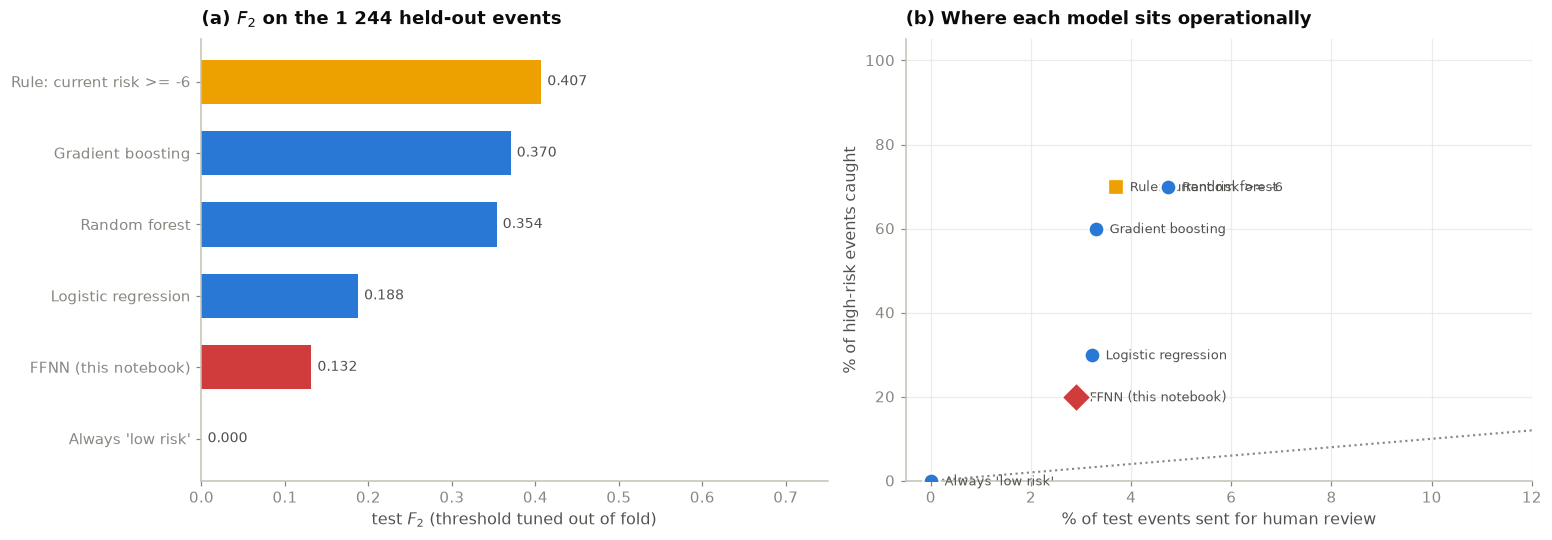

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
order = benchmark.sort_values("f2")
colors = [ps.STATUS["critical"] if "FFNN" in m else
          (ps.SERIES[3] if m.startswith("Rule") else ps.SERIES[0])
          for m in order["model"]]

ax = axes[0]
bars = ax.barh(order["model"], order["f2"], color=colors, height=0.62)
ax.bar_label(bars, fmt="{:.3f}".format, fontsize=9, color=ps.INK_SECONDARY, padding=4)
ax.set_xlabel(r"test $F_2$ (threshold tuned out of fold)")
ax.set_xlim(0, max(0.75, order["f2"].max() * 1.3))
ax.set_title(r"(a) $F_2$ on the 1 244 held-out events")
ps.grid_x_only(ax)

ax = axes[1]
for _, r in benchmark.iterrows():
    is_ffnn = "FFNN" in r["model"]
    is_rule = r["model"].startswith("Rule")
    ax.scatter(100 * r["frac_reviewed"], 100 * r["recall"],
               s=190 if is_ffnn else 110,
               color=ps.STATUS["critical"] if is_ffnn else (ps.SERIES[3] if is_rule else ps.SERIES[0]),
               edgecolors="white", linewidths=1.5, zorder=4,
               marker="D" if is_ffnn else ("s" if is_rule else "o"))
    ax.annotate(r["model"], (100 * r["frac_reviewed"], 100 * r["recall"]),
                textcoords="offset points", xytext=(9, -3), fontsize=8.5,
                color=ps.INK_SECONDARY)
ax.plot([0, 100], [0, 100], color=ps.INK_MUTED, linestyle=":", linewidth=1.4)
ax.set_xlabel("% of test events sent for human review")
ax.set_ylabel("% of high-risk events caught")
ax.set_xlim(-0.5, max(12, 100 * benchmark["frac_reviewed"].max() * 1.5))
ax.set_ylim(0, 105)
ax.set_title("(b) Where each model sits operationally")
ax.grid(True, alpha=0.6)

ps.save_fig(fig, "11_benchmark", RESULTS_DIR)
plt.show()

## Summary

* With 66 positive events in the whole dataset, **fold-to-fold scatter swamps
  the differences between activation functions, initialisers and
  architectures.** The honest reading of §3 and §5 is that none of these
  choices is resolvable at this sample size; reporting a single validation
  split would have manufactured a winner out of noise.
* **The decision threshold matters far more than the network.** Moving it
  traverses the entire recall/precision range (§7), while every architectural
  choice moves $F_2$ by less than one standard deviation. A safety rule of
  95 % recall is not attainable out of fold without flagging nearly every
  event: a few high-risk events look entirely benign two days out.
* **Putting $F_2$ into the loss is a second-order effect** (§4): the
  penalty, focal and ratio variants all rank the events about as well as
  weighted BCE; they mostly move the probability scale, which the threshold
  step absorbs anyway.
* **Early stopping is the operative regulariser.** Validation PR-AUC peaks
  within a few epochs (§9), which is why the weight-decay sweep is flat (§6).
* The **current risk estimate carries most of the signal** (§8), and the
  untrained rule "flag if current risk $\ge -6$" is a genuinely competitive
  baseline (§11) — a result worth stating plainly rather than burying.

Limitations: 10 positive events in the test split, so every test number has a
standard error of several points; the architecture and threshold were chosen on
the same development set, so the test score is mildly optimistic; and the PCA
threshold (95 %) was fixed rather than tuned.